<a href="https://colab.research.google.com/github/andarahabibie/DataScienceToolsEcosystem/blob/main/Ektraksi_Informasi_Dari_teks_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Naive Bayes Method:
Confusion Matrix:
[[12  3  4]
 [ 0  4  2]
 [ 6  0 11]]
Accuracy: 0.64
Precision: 0.63
Recall: 0.65
F1 Score: 0.64


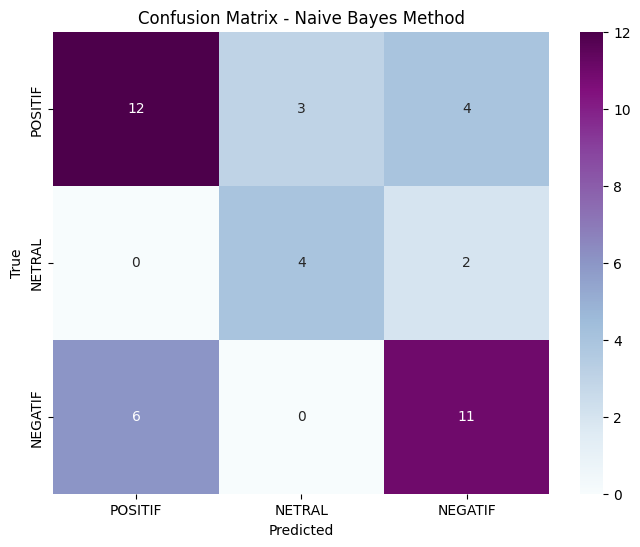


Actual vs Predicted:
Actual: NEGATIF, Predicted: NEGATIF
Actual: NEGATIF, Predicted: NEGATIF
Actual: POSITIF, Predicted: POSITIF
Actual: NEGATIF, Predicted: NEGATIF
Actual: POSITIF, Predicted: POSITIF
Actual: NEGATIF, Predicted: POSITIF
Actual: POSITIF, Predicted: POSITIF
Actual: POSITIF, Predicted: NEGATIF
Actual: POSITIF, Predicted: NEGATIF
Actual: POSITIF, Predicted: POSITIF
Actual: POSITIF, Predicted: POSITIF
Actual: POSITIF, Predicted: POSITIF
Actual: NETRAL, Predicted: NEGATIF
Actual: POSITIF, Predicted: NETRAL
Actual: NEGATIF, Predicted: NEGATIF
Actual: POSITIF, Predicted: POSITIF
Actual: NEGATIF, Predicted: NEGATIF
Actual: NEGATIF, Predicted: POSITIF
Actual: POSITIF, Predicted: POSITIF
Actual: POSITIF, Predicted: POSITIF
Actual: NETRAL, Predicted: NETRAL
Actual: NEGATIF, Predicted: NEGATIF
Actual: NEGATIF, Predicted: NEGATIF
Actual: NETRAL, Predicted: NETRAL
Actual: POSITIF, Predicted: POSITIF
Actual: POSITIF, Predicted: NEGATIF
Actual: NEGATIF, Predicted: POSITIF
Actual: POSI

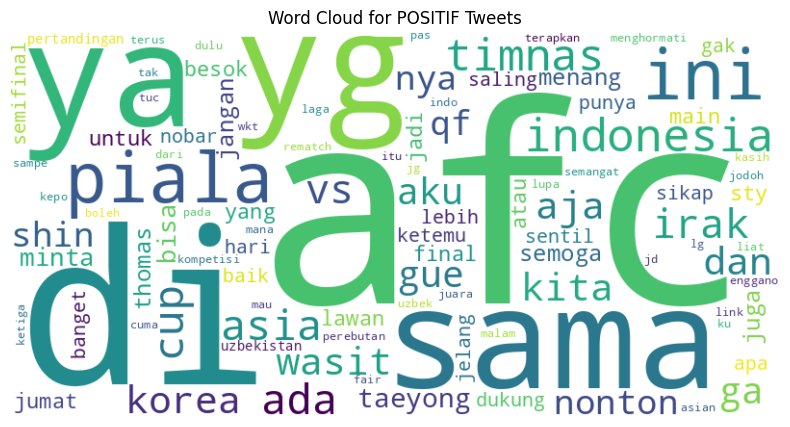


Top words in 'NETRAL' tweets:
afc: 18
ke: 5
di: 3
buat: 3
tha: 3
indonesia: 3
ah: 2
dan: 2
ada: 2
you: 2
wewe: 2
ni: 2
seperti: 2
sama: 2
sana: 2
bener: 2
cup: 2
vs: 2
harshal: 2
patel: 2
luvsk: 2
unaku: 2
shin: 2
taeyong: 2
jelang: 2
irak: 2
timnas: 2
semifinal: 2
untuk: 2
liga: 2
klub: 2
yang: 2
sepakbola: 2
era: 2
alun: 2
walter: 1
oliwa: 1
mukulu: 1
shardul: 1
poi: 1
oombu: 1
ithu: 1
serupu: 1
id: 1
serahkan: 1
semuanya: 1
tangan: 1
tuhan: 1
jangan: 1
kebencian: 1
terhadap: 1
siapa: 1
pun: 1
atau: 1
or: 1
kuku: 1
rest: 1
nah: 1
fr: 1
duloh: 1
usijinx: 1
mzee: 1
ngoja: 1
season: 1
iishe: 1
german: 1
riss: 1
coyg: 1
take: 1
ngl: 1
wanasema: 1
falaaa: 1
kita: 1
balas: 1
kemaren: 1
udh: 1
trust: 1
issue: 1
wasit: 1
ahahha: 1
kajinga: 1
kasian: 1
korsel: 1
disingkirkan: 1
king: 1
indo: 1
thomas: 1
benjamin: 1
sesko: 1
part: 1
nih: 1
ali: 1
bhai: 1
hattrick: 1
six: 1
iya: 1
semenjak: 1
ac: 1
rcti: 1
expand: 1


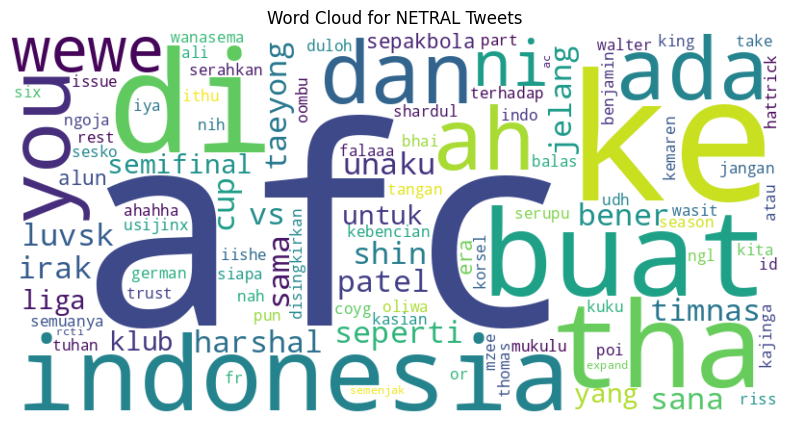


Top words in 'NEGATIF' tweets:
afc: 61
di: 25
indonesia: 23
wasit: 19
dan: 18
yang: 16
dari: 15
vs: 15
timnas: 12
ke: 12
ini: 12
irak: 12
asia: 10
uzbekistan: 10
laga: 10
untuk: 9
ada: 9
pada: 9
ga: 8
piala: 8
taeyong: 7
shin: 7
akan: 7
jadi: 7
kita: 6
lolos: 6
indo: 6
pemain: 6
juara: 5
final: 5
kalah: 5
buat: 5
cup: 5
tidak: 5
gak: 5
tim: 5
kalo: 5
dia: 5
itu: 5
bisa: 5
olimpiade: 5
melawan: 5
masih: 5
lagi: 5
harus: 5
semifinal: 5
jangan: 5
var: 5
saya: 5
kepada: 4
lg: 4
tau: 4
paris: 4
lain: 4
pertandingan: 4
yg: 4
perebutan: 4
thailand: 4
kali: 4
mafia: 4
jepang: 3
sampe: 3
thomas: 3
pelatih: 3
melakukan: 3
banget: 3
bakal: 3
gimana: 3
coach: 3
orang: 3
football: 3
klub: 3
oleh: 3
tlg: 3
korsel: 3
juga: 3
bukannya: 3
asian: 3
protes: 3
mereka: 3
fifa: 3
nanti: 3
ketiga: 3
nobar: 3
asal: 3
sty: 3
tekanan: 3
sivakorn: 3
kompetisi: 3
aku: 3
referee: 3
berkembang: 3
goblok: 3
kena: 2
netizen: 2
al: 2
aff: 2
perempat: 2
meskipun: 2
akhirnya: 2


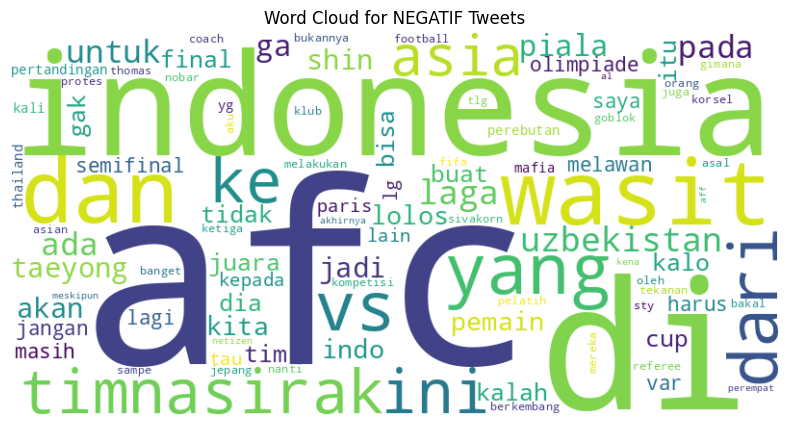

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from wordcloud import WordCloud

# Membaca file Excel
file_path = '/content/sample_data/hasillexicon.xlsx'  # Ganti dengan path file yang telah di-upload
data = pd.read_excel(file_path)

# Pastikan file Excel memiliki kolom 'tweet' dan 'labeling'
texts = data['tweet'].tolist()
true_labels = data['label'].tolist()

# Ekstraksi fitur menggunakan CountVectorizer
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(texts)
y = true_labels

# Membagi data menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Melatih model Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Prediksi dengan model Naive Bayes
predicted_labels_nb = nb_model.predict(X_test)

# Hitung confusion matrix dan metrik evaluasi untuk metode Naive Bayes
conf_matrix_nb = confusion_matrix(y_test, predicted_labels_nb, labels=['POSITIF', 'NETRAL', 'NEGATIF'])
accuracy_nb = accuracy_score(y_test, predicted_labels_nb)
precision_nb = precision_score(y_test, predicted_labels_nb, average='macro')
recall_nb = recall_score(y_test, predicted_labels_nb, average='macro')
f1_nb = f1_score(y_test, predicted_labels_nb, average='macro')

# Tampilkan hasil untuk metode Naive Bayes
print("Naive Bayes Method:")
print("Confusion Matrix:")
print(conf_matrix_nb)
print(f"Accuracy: {accuracy_nb:.2f}")
print(f"Precision: {precision_nb:.2f}")
print(f"Recall: {recall_nb:.2f}")
print(f"F1 Score: {f1_nb:.2f}")

# Plot confusion matrix untuk metode Naive Bayes
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_nb, annot=True, fmt='d', cmap='BuPu', xticklabels=['POSITIF', 'NETRAL', 'NEGATIF'], yticklabels=['POSITIF', 'NETRAL', 'NEGATIF'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - Naive Bayes Method')
plt.show()

# Tampilkan beberapa nilai aktual dan prediksi
print("\nActual vs Predicted:")
for actual, predicted in zip(y_test[:30], predicted_labels_nb[:30]):
    print(f"Actual: {actual}, Predicted: {predicted}")

# Jika Anda ingin menampilkan keseluruhan dalam bentuk tabel
result_df = pd.DataFrame({'Actual': y_test, 'Predicted': predicted_labels_nb})
print(result_df.head(10))  # Tampilkan 10 baris pertama

# Analisis kata-kata yang sering muncul
def get_top_n_words(corpus, n=None):
    vec = CountVectorizer().fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return dict(words_freq[:n])

# Membuat word cloud
def plot_wordcloud(data, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(data)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

# Kata-kata yang sering muncul untuk masing-masing kategori
categories = ['POSITIF', 'NETRAL', 'NEGATIF']
for category in categories:
    category_texts = [texts[i] for i in range(len(texts)) if y[i] == category]
    top_words = get_top_n_words(category_texts, n=100)  # Mengambil 100 kata teratas
    print(f"\nTop words in '{category}' tweets:")
    for word, freq in top_words.items():
        print(f"{word}: {freq}")
    plot_wordcloud(top_words, f'Word Cloud for {category} Tweets')